# Introduction - Exploratory Analysis

In this notebook, we will conduct an analysis of the data previously prepared in the path: `data/interim/hockey_teams.json`. This file, being partially processed, is easily accessible for import and ready for more detailed analytical examination.

This part of the workshop will focus on utilizing `pandas` and `matplotlib`, which were discussed during the course. The main objective is to familiarize ourselves with the dataset we are working on. Through a series of exercises:  
- we will get to know the structure of the data,  
- we will conduct elementary data exploration (EDA).

## Column Description

Below is a brief description of each column in our dataset:

- **Team Name**: The name of the team participating in the match.
- **Year**: The year in which the season takes place.
- **Wins**: The number of matches won by the team in the given season.
- **Losses**: The number of matches lost by the team in the given season.
- **OT Losses**: The number of matches lost by the team in overtime in the given season.
- **Win %**: The percentage of matches won by the team in the given season.
- **Goals For (GF)**: The number of goals scored by the team in the given season.
- **Goals Against (GA)**: The number of goals conceded by the team in the given season.
- **+ / -**: The difference between the number of goals scored and conceded by the team in the given season.

> Note: At this stage, certain significant simplifications were intentionally made in the analysis and they will not be explicitly mentioned, aiming for a discussion at the end of the workshop.

# Preparation

## Import libraries
Here, load the libraries that will be needed in the following steps

# Loading the Dataset

We recommend loading the raw data into a variable with the suffix `_raw`. This will avoid the need to reload the data from the beginning in case of an error, which can be a time-consuming process.  
  
> **Tip:** A `json` file can be easily loaded using `pandas` with the `read_json` function - [click](https://pandas.pydata.org/docs/reference/api/pandas.read_json.html)  

Load data from the `hockey_teams` file here

In [1]:
import pandas as pd
import requests
from bs4 import BeautifulSoup

url = f"https://www.scrapethissite.com/pages/forms/?page_num=1"

response = requests.get(url)
soup = BeautifulSoup(response.text, "html.parser")
headers = [header.text.strip() for header in soup.find_all('th')]

dict_data = {header: [] for header in headers}

for page in range(1, 25):
    print(f"Zpracovava se stranka {page}")
    url = f"https://www.scrapethissite.com/pages/forms/?page_num={page}"
    response = requests.get(url)
    soup = BeautifulSoup(response.text, "html.parser")
    table_rows = soup.find_all('tr', class_='team')

    for row in table_rows:
        row_values = [value.text.strip() for value in row.find_all('td')]

        for key, value in zip(dict_data, row_values):
            dict_data[key].append(value)


df_data = pd.DataFrame(dict_data)

Zpracovava se stranka 1
Zpracovava se stranka 2
Zpracovava se stranka 3
Zpracovava se stranka 4
Zpracovava se stranka 5
Zpracovava se stranka 6
Zpracovava se stranka 7
Zpracovava se stranka 8
Zpracovava se stranka 9
Zpracovava se stranka 10
Zpracovava se stranka 11
Zpracovava se stranka 12
Zpracovava se stranka 13
Zpracovava se stranka 14
Zpracovava se stranka 15
Zpracovava se stranka 16
Zpracovava se stranka 17
Zpracovava se stranka 18
Zpracovava se stranka 19
Zpracovava se stranka 20
Zpracovava se stranka 21
Zpracovava se stranka 22
Zpracovava se stranka 23
Zpracovava se stranka 24


Check here if the data loaded correctly

In [2]:
df = df_data.copy()

In [3]:
df

,Team Name,Year,Wins,Losses,OT Losses,Win %,Goals For (GF),Goals Against (GA),+ / -
0,Boston Bruins,1990,44,24,,0.55,299,264,35
1,Buffalo Sabres,1990,31,30,,0.388,292,278,14
2,Calgary Flames,1990,46,26,,0.575,344,263,81
3,Chicago Blackhawks,1990,49,23,,0.613,284,211,73
4,Detroit Red Wings,1990,34,38,,0.425,273,298,-25
...,...,...,...,...,...,...,...,...,...
577,Tampa Bay Lightning,2011,38,36,8,0.463,235,281,-46
578,Toronto Maple Leafs,2011,35,37,10,0.427,231,264,-33
579,Vancouver Canucks,2011,51,22,9,0.622,249,198,51
580,Washington Capitals,2011,42,32,8,0.512,222,230,-8


# Preliminary Data Transformation

## Standardizing Column Names

Currently, our dataset contains original column names which, from a technical standpoint, should not contain spaces or other special characters.

In this section, we will standardize and simplify the naming conventions to facilitate data processing in subsequent stages. We will apply the following column name mapping:

- **Team Name** -> `team`
- **Year** -> `season`
- **Wins** -> `victories`
- **Losses** -> `defeats`
- **OT Losses** -> `overtime_defeats`
- **Win %** -> `victory_percentage`
- **Goals For (GF)** -> `scored_goals`
- **Goals Against (GA)** -> `received_goals`
- **\+ / -** -> `goal_difference`

> At this point, we recommend creating a new DataFrame without the `_raw` postfix. For example, if the data was loaded into the variable `df_raw`, we now want to work with the variable `df`, where we will modify the column names.

In [4]:
df = df.rename(columns={'Team Name': 'team', 'Year': 'season', "Wins": "victories", "Losses" :  "defeats", "OT Losses" : "overtime_defeats", "Win %" : "victory_percentage", "Goals For (GF)" : "scored_goals", "Goals Against (GA)" : "received_goals", "+ / -" : "goal_difference" })

In [5]:
df

,team,season,victories,defeats,overtime_defeats,victory_percentage,scored_goals,received_goals,goal_difference
0,Boston Bruins,1990,44,24,,0.55,299,264,35
1,Buffalo Sabres,1990,31,30,,0.388,292,278,14
2,Calgary Flames,1990,46,26,,0.575,344,263,81
3,Chicago Blackhawks,1990,49,23,,0.613,284,211,73
4,Detroit Red Wings,1990,34,38,,0.425,273,298,-25
...,...,...,...,...,...,...,...,...,...
577,Tampa Bay Lightning,2011,38,36,8,0.463,235,281,-46
578,Toronto Maple Leafs,2011,35,37,10,0.427,231,264,-33
579,Vancouver Canucks,2011,51,22,9,0.622,249,198,51
580,Washington Capitals,2011,42,32,8,0.512,222,230,-8


## Removing Empty Values

As can be observed, the `overtime_defeats` column contains many empty values, and the expected data type is `int`. Before proceeding with further analysis, this column needs to be properly prepared.

To achieve this, we will perform the following steps:
- Check which symbol is used as an indicator of an empty field.
- Fill the empty fields with a value of 0.
- Then convert the data type of this column to `int`.

By following these steps, the `overtime_defeats` column will be ready for further analysis.

### Finding the Indicator of an Empty Field

### Overwriting Empty Values with 0

In [43]:
df["overtime_defeats"] = (df["overtime_defeats"].replace(["overtime_defeats", "", " ", "NaN", "None"], np.nan)
    .fillna(0)
)

In [44]:
df["overtime_defeats"] = df["overtime_defeats"].astype(int)

In [45]:
df

,team,season,victories,defeats,overtime_defeats,victory_percentage,scored_goals,received_goals,goal_difference
0,Boston Bruins,1990,44,24,0,0.55,299,264,35
1,Buffalo Sabres,1990,31,30,0,0.388,292,278,14
2,Calgary Flames,1990,46,26,0,0.575,344,263,81
3,Chicago Blackhawks,1990,49,23,0,0.613,284,211,73
4,Detroit Red Wings,1990,34,38,0,0.425,273,298,-25
...,...,...,...,...,...,...,...,...,...
577,Tampa Bay Lightning,2011,38,36,8,0.463,235,281,-46
578,Toronto Maple Leafs,2011,35,37,10,0.427,231,264,-33
579,Vancouver Canucks,2011,51,22,9,0.622,249,198,51
580,Washington Capitals,2011,42,32,8,0.512,222,230,-8


### Column Type Conversion

35


# Dataset Analysis

In this section, we will focus on answering fundamental questions about our dataset in the context of hockey games. The goal is to become familiar with the dataset and develop an intuition about it.  
  
Here is a list of exercises we will perform to find answers to key questions:  
  
- How many teams have participated in league games over the years?  
- What is the total number of available seasons?  
- What is the time span of the data?  
- Are there any suspicious or outlier values in the numerical columns?  
  
These exercises will help us better understand the structure and nature of our data.  




### Number of teams that participated in league matches

Here, indicate the total number of teams available in our dataset

In [32]:
print(df["team"].nunique())
# 35 tymu

35


In [33]:
print(df["season"].nunique())
# 21 sezon

21


In [40]:
timespan = int(df["season"].max()) - int(df["season"].min())
print(timespan)
print(df["season"].min())
print(df["season"].max())
#21 let
# od roku 1990 do 2011

21
1990
2011


In [111]:
df["victories"] = df["victories"].astype(int)
df["defeats"] = df["defeats"].astype(int)
df["scored_goals"] = df["scored_goals"].astype(int)
df["victory_percentage"] = df["victory_percentage"].astype(float)
df["goal_difference"] = df["goal_difference"].astype(int)
df["season"] = df["season"].astype(int)
df["received_goals"] = df["received_goals"].astype(int)


In [109]:
df

,team,season,victories,defeats,overtime_defeats,victory_percentage,scored_goals,received_goals,goal_difference
0,Boston Bruins,1990,44,24,0,0.550,299,264,35
1,Buffalo Sabres,1990,31,30,0,0.388,292,278,14
2,Calgary Flames,1990,46,26,0,0.575,344,263,81
3,Chicago Blackhawks,1990,49,23,0,0.613,284,211,73
4,Detroit Red Wings,1990,34,38,0,0.425,273,298,-25
...,...,...,...,...,...,...,...,...,...
577,Tampa Bay Lightning,2011,38,36,8,0.463,235,281,-46
578,Toronto Maple Leafs,2011,35,37,10,0.427,231,264,-33
579,Vancouver Canucks,2011,51,22,9,0.622,249,198,51
580,Washington Capitals,2011,42,32,8,0.512,222,230,-8


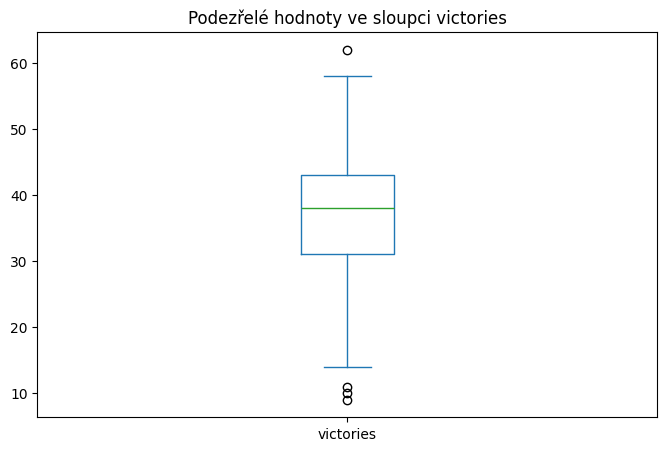

In [47]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
df["victories"].plot(kind="box")
plt.title("Podezřelé hodnoty ve sloupci victories")
plt.show()

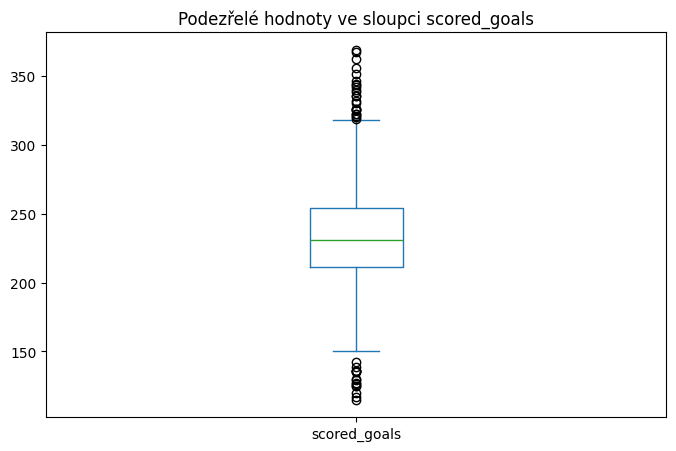

In [64]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
df["scored_goals"].plot(kind="box")
plt.title("Podezřelé hodnoty ve sloupci scored_goals")
plt.show()

In [81]:
df[df["scored_goals"]>350]

,team,season,victories,defeats,overtime_defeats,victory_percentage,scored_goals,received_goals,goal_difference
47,Detroit Red Wings,1992,47,28,0,0.560,369,280,89
58,Pittsburgh Penguins,1992,56,21,0,0.667,367,268,99
59,Quebec Nordiques,1992,47,27,0,0.560,351,300,51
73,Detroit Red Wings,1993,46,30,0,0.548,356,275,81
137,Pittsburgh Penguins,1995,49,29,0,0.598,362,284,78


In [69]:
df[df["scored_goals"]<125]

,team,season,victories,defeats,overtime_defeats,victory_percentage,scored_goals,received_goals,goal_difference
101,Florida Panthers,1994,20,22,0,0.417,115,127,-12
108,Ottawa Senators,1994,9,34,0,0.188,117,174,-57
114,Tampa Bay Lightning,1994,17,28,0,0.354,120,144,-24


In [59]:
df[df["victories"] > 53]


,team,season,victories,defeats,overtime_defeats,victory_percentage,scored_goals,received_goals,goal_difference
58,Pittsburgh Penguins,1992,56,21,0,0.667,367,268,99
126,Detroit Red Wings,1995,62,13,0,0.756,325,181,144
382,Detroit Red Wings,2005,58,16,8,0.707,305,209,96
442,Detroit Red Wings,2007,54,21,7,0.659,257,184,73
521,Washington Capitals,2009,54,15,13,0.659,318,233,85
550,Vancouver Canucks,2010,54,19,9,0.659,262,185,77


In [61]:
df[df["victories"] < 15]

,team,season,victories,defeats,overtime_defeats,victory_percentage,scored_goals,received_goals,goal_difference
56,Ottawa Senators,1992,10,70,0,0.119,202,395,-193
60,San Jose Sharks,1992,11,71,0,0.131,218,414,-196
82,Ottawa Senators,1993,14,61,0,0.167,201,397,-196
108,Ottawa Senators,1994,9,34,0,0.188,117,174,-57
225,Atlanta Thrashers,1999,14,57,4,0.171,170,313,-143


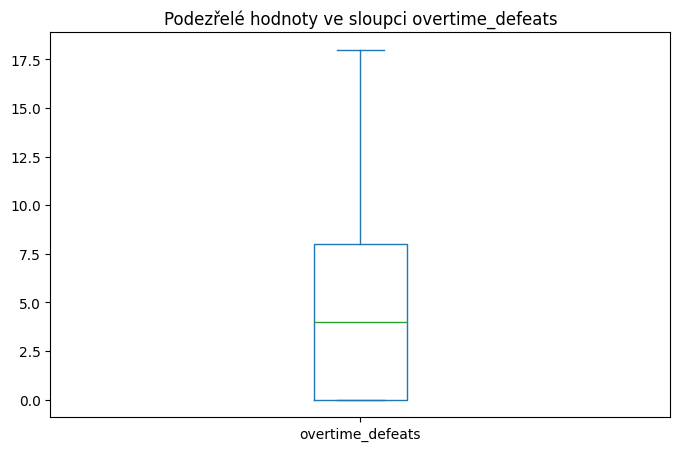

In [74]:
plt.figure(figsize=(8,5))
df["overtime_defeats"].plot(kind="box")
plt.title("Podezřelé hodnoty ve sloupci overtime_defeats")
plt.show()

In [77]:
df[df["overtime_defeats"]>= 17]

,team,season,victories,defeats,overtime_defeats,victory_percentage,scored_goals,received_goals,goal_difference
488,Tampa Bay Lightning,2008,24,40,18,0.293,210,279,-69
563,Florida Panthers,2011,38,26,18,0.463,203,227,-24


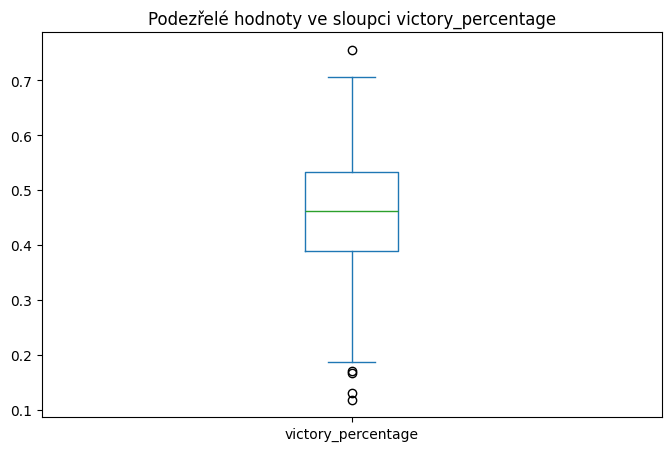

In [82]:
plt.figure(figsize=(8,5))
df["victory_percentage"].plot(kind="box")
plt.title("Podezřelé hodnoty ve sloupci victory_percentage")
plt.show()

In [85]:
df[df["victory_percentage"]<=0.15]

,team,season,victories,defeats,overtime_defeats,victory_percentage,scored_goals,received_goals,goal_difference
56,Ottawa Senators,1992,10,70,0,0.119,202,395,-193
60,San Jose Sharks,1992,11,71,0,0.131,218,414,-196


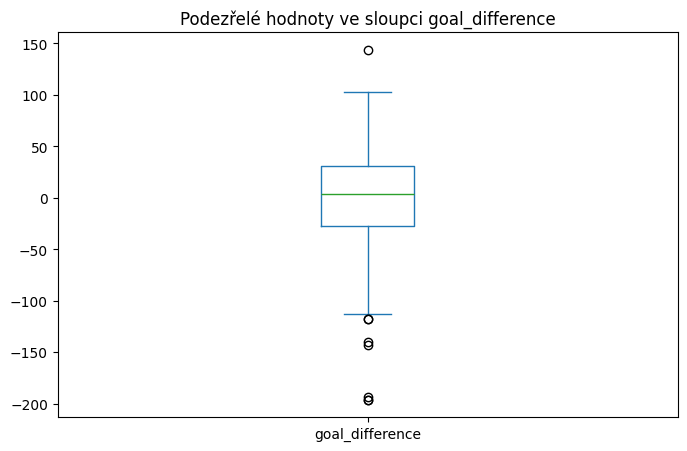

In [91]:
plt.figure(figsize=(8,5))
df["goal_difference"].plot(kind="box")
plt.title("Podezřelé hodnoty ve sloupci goal_difference")
plt.show()

In [96]:
df[df["goal_difference"] > 90]

,team,season,victories,defeats,overtime_defeats,victory_percentage,scored_goals,received_goals,goal_difference
58,Pittsburgh Penguins,1992,56,21,0,0.667,367,268,99
126,Detroit Red Wings,1995,62,13,0,0.756,325,181,144
269,New Jersey Devils,2000,48,19,3,0.585,295,195,100
382,Detroit Red Wings,2005,58,16,8,0.707,305,209,96
392,Ottawa Senators,2005,52,21,9,0.634,314,211,103


In [98]:
df[df["goal_difference"]< -160]

,team,season,victories,defeats,overtime_defeats,victory_percentage,scored_goals,received_goals,goal_difference
56,Ottawa Senators,1992,10,70,0,0.119,202,395,-193
60,San Jose Sharks,1992,11,71,0,0.131,218,414,-196
82,Ottawa Senators,1993,14,61,0,0.167,201,397,-196


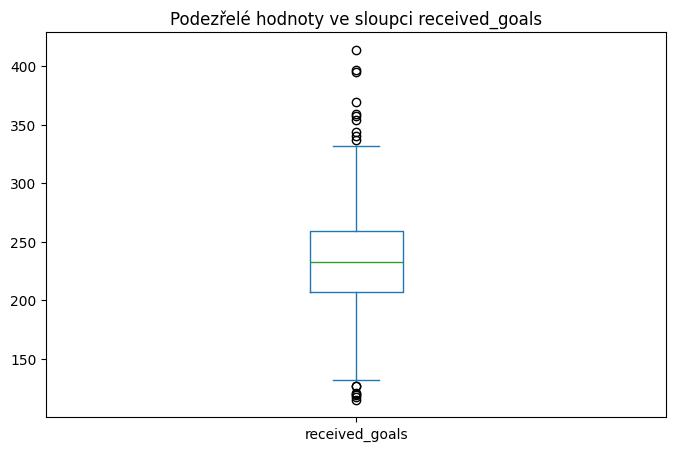

In [113]:
plt.figure(figsize=(8,5))
df["received_goals"].plot(kind="box")
plt.title("Podezřelé hodnoty ve sloupci received_goals")
plt.show()

In [114]:
df[df["received_goals"]>380]

,team,season,victories,defeats,overtime_defeats,victory_percentage,scored_goals,received_goals,goal_difference
56,Ottawa Senators,1992,10,70,0,0.119,202,395,-193
60,San Jose Sharks,1992,11,71,0,0.131,218,414,-196
82,Ottawa Senators,1993,14,61,0,0.167,201,397,-196


In [116]:
df[df["received_goals"]<120]

,team,season,victories,defeats,overtime_defeats,victory_percentage,scored_goals,received_goals,goal_difference
95,Buffalo Sabres,1994,22,19,0,0.458,130,119,11
97,Chicago Blackhawks,1994,24,19,0,0.500,156,115,41
99,Detroit Red Wings,1994,33,11,0,0.688,180,117,63


**ODLEHLE HODNOTY**
---

-----


VICTORIES MAX

Detroit Red Wings 1995 // 62

Detroit Red Wings 2005 // 56

Detroit Red Wings 2007 // 54

Pittsburgh Penguins 1992 // 56

----

VICTORIES MIN

Ottawa Senators 1992 // 10

Ottawa Senators 1993 // 14

Ottawa Senators 1994 // 9

San Jose Sharks	1992 // 11

----
SCORED GOALS MAX

Detroit Red Wings	1992 // 369

Pittsburgh Penguins	1992 // 367

Quebec Nordiques	1992 // 351

Detroit Red Wings	1993 // 356

Pittsburgh Penguins	1995 // 362

---

SCORED GOALS MIN

Florida Panthers	1994 // 115

Ottawa Senators	1994 // 117

Tampa Bay Lightning	1992 // 120


----

DEFEATS MAX

Ottawa Senators	1992 // 70

San Jose Sharks	1992 // 71

----

DEFEATS MIN

Detroit Red Wings	1994 // 11

Quebec Nordiques	1994 // 13

Detroit Red Wings	1995 // 13

----

OVERTIME DEFEATS

Tampa Bay Lightning	2008 // 18

Florida Panthers	2011 // 18

------

VICTORY % VIC JAK 70%

Detroit Red Wings	1995 // 0.756 // 75.6%

Detroit Red Wings	2005 // 0.707 // 70.7%

-----

VICTORY % MENE JAK 15%

Ottawa Senators	1992 // 0.119 // 11.9%

San Jose Sharks	1992 // 0.131 // 13.1%


----

GOAL DIFFERENCE + MAX

Detroit Red Wings	1995 // 144

dalsi je az

Ottawa Senators 2005 // 103

----

GOAL DIFFERENCE - MAX

Ottawa Senators	1992 // -193

San Jose Sharks	1992 // -196

Ottawa Senators	1993 // -196

-----

REICEVED GOALS MAX

Ottawa Senators	1992 // 395

San Jose Sharks	1992 // 414

Ottawa Senators	1993 //	397

-----

REICEVED GOALS MIN

95	Buffalo Sabres	1994 // 119

97	Chicago Blackhawks	1994 // 115

99	Detroit Red Wings	1994 // 117



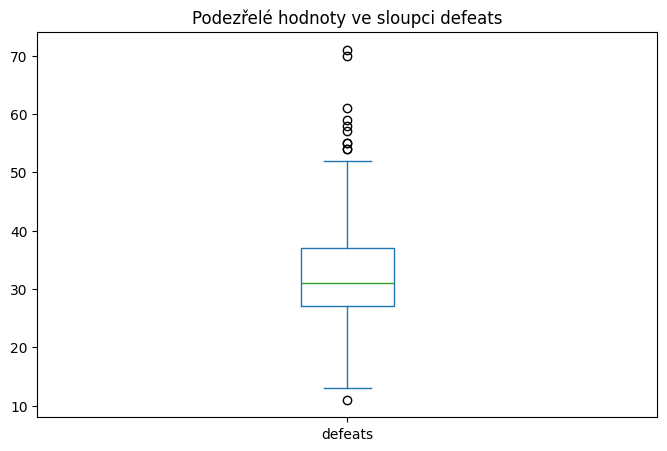

In [50]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
df["defeats"].plot(kind="box")
plt.title("Podezřelé hodnoty ve sloupci defeats")
plt.show()

In [70]:
df[df["defeats"]>65]

,team,season,victories,defeats,overtime_defeats,victory_percentage,scored_goals,received_goals,goal_difference
56,Ottawa Senators,1992,10,70,0,0.119,202,395,-193
60,San Jose Sharks,1992,11,71,0,0.131,218,414,-196


In [71]:
df[df["defeats"]<15]

,team,season,victories,defeats,overtime_defeats,victory_percentage,scored_goals,received_goals,goal_difference
99,Detroit Red Wings,1994,33,11,0,0.688,180,117,63
111,Quebec Nordiques,1994,30,13,0,0.625,185,134,51
126,Detroit Red Wings,1995,62,13,0,0.756,325,181,144


### Total number of seasons

Here, indicate the total number of seasons.

In [86]:
print(df["season"].nunique())

21


### Time Span of Data

Here, we will examine the availability of data for individual seasons. The analysis will be conducted in two stages:  
- First, we will determine the time range of the data by identifying the start year (`start_year`) and the end year (`end_year`). This will allow us to establish for which seasons we have information.  
- Next, we will look for any gaps in the time data to ensure that we have a complete set of information for each season.   

At this point, we will determine the start year and end year of the data:

In [87]:
timespan = int(df["season"].max()) - int(df["season"].min())
print(timespan)
print(df["season"].min())
print(df["season"].max())


21
1990
2011


In [88]:
df["season"].unique()

array(['1990', '1991', '1992', '1993', '1994', '1995', '1996', '1997',
       '1998', '1999', '2000', '2001', '2002', '2003', '2005', '2006',
       '2007', '2008', '2009', '2010', '2011'], dtype=object)

Here, we will check if data is present for each year within the determined range: 1990 - 2011

### Analysis of Numerical Columns

Here we will examine the basic descriptive statistics for numerical columns.

To this end, describe and analyze the results for the following columns:

- victories
- defeats
- 1
- victory_percentage
- scored_goals
- received_goals
- goal_difference

We are interested in the following statistics:
- mean,
- count,
- standard deviation,
- percentiles = `[0, 0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 1]`

In [120]:
avgs = df.groupby("team")[["victories", "defeats", "overtime_defeats", "victory_percentage", "scored_goals", "received_goals", "goal_difference"]].mean()
counts = df.groupby("team")[["victories", "defeats", "overtime_defeats", "victory_percentage", "scored_goals", "received_goals", "goal_difference"]].count()
stdevs = df.groupby("team")[["victories", "defeats", "overtime_defeats", "victory_percentage", "scored_goals", "received_goals", "goal_difference"]].std()


In [141]:
avgs

,victories,defeats,overtime_defeats,victory_percentage,scored_goals,received_goals,goal_difference
team,,,,,,,
Anaheim Ducks,42.833333,29.666667,9.500000,0.522333,231.500000,225.666667,5.833333
Atlanta Thrashers,31.090909,39.727273,7.090909,0.379182,224.090909,274.000000,-49.909091
Boston Bruins,38.857143,29.238095,5.047619,0.484905,241.619048,229.666667,11.952381
Buffalo Sabres,38.238095,30.857143,3.952381,0.475143,241.714286,223.523810,18.190476
Calgary Flames,36.380952,32.142857,4.476190,0.453476,234.285714,233.142857,1.142857
Carolina Hurricanes,36.785714,32.928571,6.142857,0.448500,221.714286,232.428571,-10.714286
Chicago Blackhawks,36.428571,32.142857,4.380952,0.454286,232.142857,226.571429,5.571429
Colorado Avalanche,42.312500,28.875000,4.500000,0.516062,246.187500,220.875000,25.312500
Columbus Blue Jackets,31.090909,40.090909,7.818182,0.379182,201.818182,249.454545,-47.636364


In [133]:
avgs_pivot = pd.pivot_table(
    df,
    index="team",
    columns="season",
    values=["victories", "defeats", "overtime_defeats", "victory_percentage", "scored_goals", "received_goals", "goal_difference"],
    aggfunc="mean"
)


In [138]:
avgs_pivot["victories"]

season,1990,1991,1992,1993,1994,1995,1996,1997,1998,1999,...,2001,2002,2003,2005,2006,2007,2008,2009,2010,2011
team,,,,,,,,,,,,,,,,,,,,,
Anaheim Ducks,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,48.0,47.0,42.0,39.0,47.0,34.0
Atlanta Thrashers,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,14.0,...,19.0,31.0,33.0,41.0,43.0,34.0,35.0,35.0,34.0,NaN
Boston Bruins,44.0,36.0,51.0,42.0,27.0,40.0,26.0,39.0,39.0,24.0,...,43.0,36.0,41.0,29.0,35.0,41.0,53.0,39.0,46.0,49.0
Buffalo Sabres,31.0,31.0,38.0,43.0,22.0,33.0,40.0,36.0,37.0,35.0,...,35.0,27.0,37.0,52.0,53.0,39.0,41.0,45.0,43.0,39.0
Calgary Flames,46.0,31.0,43.0,42.0,24.0,34.0,32.0,26.0,30.0,31.0,...,32.0,29.0,42.0,46.0,43.0,42.0,46.0,40.0,41.0,37.0
Carolina Hurricanes,NaN,NaN,NaN,NaN,NaN,NaN,NaN,33.0,34.0,37.0,...,35.0,22.0,28.0,52.0,40.0,43.0,45.0,35.0,40.0,33.0
Chicago Blackhawks,49.0,36.0,47.0,39.0,24.0,40.0,34.0,30.0,29.0,33.0,...,41.0,30.0,20.0,26.0,31.0,40.0,46.0,52.0,44.0,45.0
Colorado Avalanche,NaN,NaN,NaN,NaN,NaN,47.0,49.0,39.0,44.0,42.0,...,45.0,42.0,40.0,43.0,44.0,44.0,32.0,43.0,30.0,41.0
Columbus Blue Jackets,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,22.0,29.0,25.0,35.0,33.0,34.0,41.0,32.0,34.0,29.0


In [144]:
percentiles = df[["victories", "defeats", "overtime_defeats", "victory_percentage", "scored_goals", "received_goals", "goal_difference"]].quantile([0, 0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 1])
percentiles_by_team = df.groupby("team")[["victories", "defeats", "overtime_defeats", "victory_percentage", "scored_goals", "received_goals", "goal_difference"]].quantile([0, 0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 1])

In [143]:
percentiles

,victories,defeats,overtime_defeats,victory_percentage,scored_goals,received_goals,goal_difference
0.00,9.00,11.0,0.0,0.11900,115.00,115.00,-196.0
0.05,21.05,20.0,0.0,0.28030,175.05,168.05,-72.0
0.10,24.10,23.0,0.0,0.32100,190.10,187.00,-57.0
0.25,31.00,27.0,0.0,0.39000,211.00,207.00,-27.0
0.50,38.00,31.0,4.0,0.46300,231.00,232.50,4.0
0.75,43.00,37.0,8.0,0.53400,254.00,258.75,31.0
0.90,48.00,43.0,11.0,0.58500,282.90,286.00,54.0
0.95,50.00,47.0,13.0,0.62185,305.95,303.00,68.0
1.00,62.00,71.0,18.0,0.75600,369.00,414.00,144.0


In [151]:
df["team"].unique()

array(['Boston Bruins', 'Buffalo Sabres', 'Calgary Flames',
       'Chicago Blackhawks', 'Detroit Red Wings', 'Edmonton Oilers',
       'Hartford Whalers', 'Los Angeles Kings', 'Minnesota North Stars',
       'Montreal Canadiens', 'New Jersey Devils', 'New York Islanders',
       'New York Rangers', 'Philadelphia Flyers', 'Pittsburgh Penguins',
       'Quebec Nordiques', 'St. Louis Blues', 'Toronto Maple Leafs',
       'Vancouver Canucks', 'Washington Capitals', 'Winnipeg Jets',
       'San Jose Sharks', 'Ottawa Senators', 'Tampa Bay Lightning',
       'Mighty Ducks of Anaheim', 'Dallas Stars', 'Florida Panthers',
       'Colorado Avalanche', 'Phoenix Coyotes', 'Carolina Hurricanes',
       'Nashville Predators', 'Atlanta Thrashers',
       'Columbus Blue Jackets', 'Minnesota Wild', 'Anaheim Ducks'],
      dtype=object)

In [152]:
percentiles_by_team.loc["Chicago Blackhawks"]

,victories,defeats,overtime_defeats,victory_percentage,scored_goals,received_goals,goal_difference
0.00,20.0,19.0,0.0,0.244,156.0,115.0,-74.0
0.05,24.0,22.0,0.0,0.317,188.0,199.0,-71.0
0.10,26.0,23.0,0.0,0.354,192.0,207.0,-57.0
0.25,30.0,26.0,0.0,0.366,207.0,211.0,-19.0
0.50,36.0,33.0,2.0,0.464,239.0,230.0,10.0
0.75,44.0,39.0,8.0,0.537,258.0,245.0,41.0
0.90,47.0,42.0,11.0,0.561,273.0,258.0,53.0
0.95,49.0,43.0,12.0,0.613,279.0,259.0,62.0
1.00,52.0,43.0,13.0,0.634,284.0,285.0,73.0


# `team`

In this section, we will conduct a series of analyses on individual teams participating in the leagues. This will allow us to identify the teams that have performed best in the competitions over the years.


## Analysis of Team Participation in League Seasons
Let's perform the following exercises:

- Check how many teams have participated in all seasons of the selected league.
- Display the list of these teams.

In [158]:
num_seasons = df.groupby("team")["season"].count()
all_season_participants = num_seasons[num_seasons == 21]

In [168]:
list_all_s_p = []
for team, count in all_season_participants.items():
    list_all_s_p.append(team)

List of teams that participated in all seasons of hockey competitions:

In [170]:
for p in list_all_s_p:
  print(p)

Boston Bruins
Buffalo Sabres
Calgary Flames
Chicago Blackhawks
Detroit Red Wings
Edmonton Oilers
Los Angeles Kings
Montreal Canadiens
New Jersey Devils
New York Islanders
New York Rangers
Philadelphia Flyers
Pittsburgh Penguins
St. Louis Blues
Toronto Maple Leafs
Vancouver Canucks
Washington Capitals


The number of teams that have played in all seasons:

In [171]:
len(list_all_s_p)

17

## Best Performing Teams in League History

Let's list the five best teams with the highest average `victory_percentage` over all years, presenting the data broken down by individual teams and seasons.

In [190]:
top_5 = avgs["victories"].sort_values(ascending = False).head(5)

In [193]:
lst_5 = []
for team, avg in top_5.items():
  lst_5.append(team)

In [197]:
df_top5 = df[df["team"].isin(lst_5)]

In [194]:
lst_5

['Detroit Red Wings',
 'New Jersey Devils',
 'Anaheim Ducks',
 'Colorado Avalanche',
 'Dallas Stars']

In [205]:
df_top5_pivot = pd.pivot_table(
    df_top5,
    index="team",
    columns="season",
    values="victory_percentage",
    aggfunc="mean""
)


In [214]:
df_top5_pivot = df_top5_pivot*100

In [215]:
df_top5_pivot

season,1990,1991,1992,1993,1994,1995,1996,1997,1998,1999,...,2001,2002,2003,2005,2006,2007,2008,2009,2010,2011
team,,,,,,,,,,,,,,,,,,,,,
Anaheim Ducks,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,58.5,57.3,51.2,47.6,57.3,41.5
Colorado Avalanche,NaN,NaN,NaN,NaN,NaN,57.3,59.8,47.6,53.7,51.2,...,54.9,51.2,48.8,52.4,53.7,53.7,39.0,52.4,36.6,50.0
Dallas Stars,NaN,NaN,NaN,50.0,35.4,31.7,58.5,59.8,62.2,52.4,...,43.9,56.1,50.0,64.6,61.0,54.9,43.9,45.1,51.2,51.2
Detroit Red Wings,42.5,53.7,56.0,54.8,68.8,75.6,46.3,53.7,52.4,58.5,...,62.2,58.5,58.5,70.7,61.0,65.9,62.2,53.7,57.3,58.5
New Jersey Devils,40.0,47.5,47.6,56.0,45.8,45.1,54.9,58.5,57.3,54.9,...,50.0,56.1,52.4,56.1,59.8,56.1,62.2,58.5,46.3,58.5


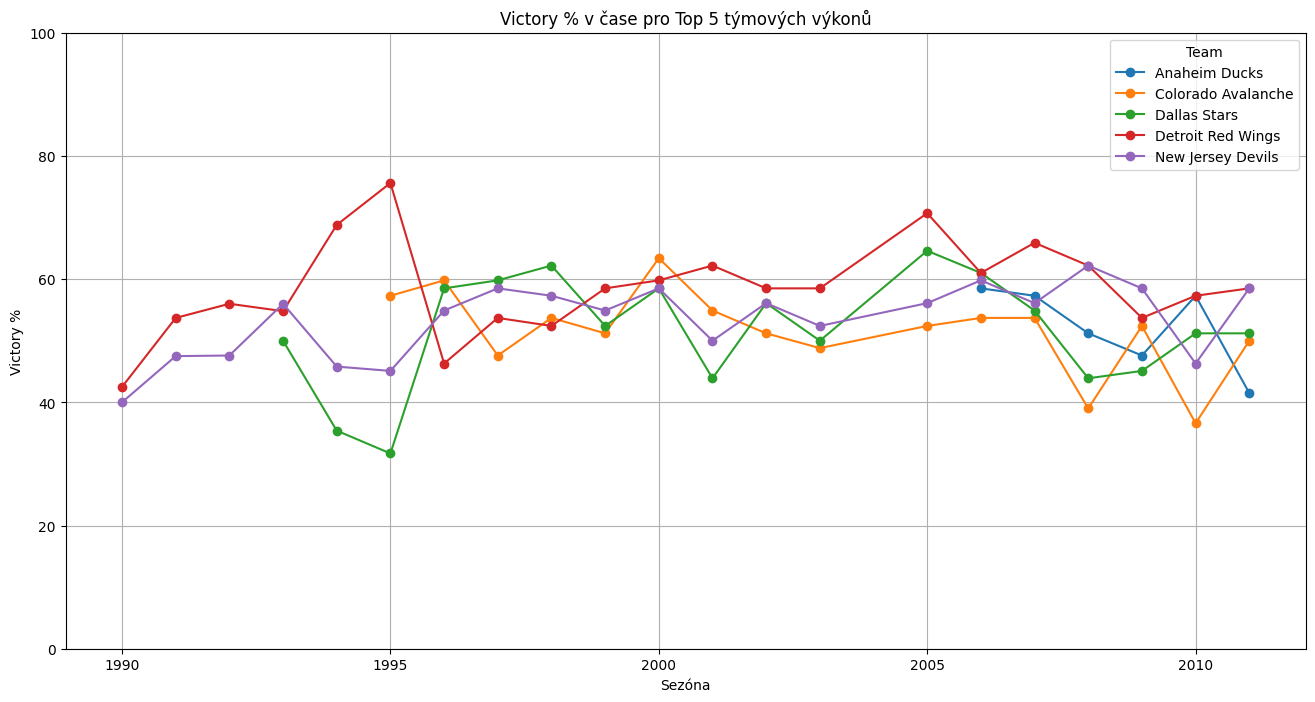

In [275]:
graph_winrate = df_top5_pivot.T.plot(figsize=(16,8), marker='o')
graph_winrate.set_title("Victory % v čase pro Top 5 týmových výkonů")
graph_winrate.set_xlabel("Sezóna")
graph_winrate.set_ylabel("Victory %")
graph_winrate.legend(title="Team")
graph_winrate.grid(True)

graph_winrate.set_ylim(0, 100)
plt.show()


## Top Teams in History

Let's determine the top 5 teams that have won the most league titles in entire history. Let's consider whether, based on the available data, we can identify a single team that unquestionably deserves the title of the best in history.

For simplicity, let's assume that the league winner is the team with the most victories in a given season.

> Hint: The information contained in the article `Pandas > Summary of the 4th Meeting > Analytical Functions` may be useful.

In [225]:
df.groupby("season")["victories"].max()

,victories
season,
1990,49
1991,50
1992,56
1993,52
1994,33
1995,62
1996,49
1997,49
1998,51


In [228]:
winners = df.sort_values(["season", "victories"], ascending=[True, False]).groupby("season").head(1)[["season", "team", "victories"]]


In [233]:
top5_winners = winners.groupby("team").count().sort_values(by = "victories", ascending = False).head(5)

In [250]:
wined = winners.groupby("team")["victories"].count()

In [253]:
won_once = []
for team, count in winned.items():
  if count == 1:
    won_once.append(team)

print(won_once)

['Boston Bruins', 'Buffalo Sabres', 'Chicago Blackhawks', 'Ottawa Senators', 'Pittsburgh Penguins', 'St. Louis Blues', 'Vancouver Canucks', 'Washington Capitals']


In [262]:
winrate = df.groupby("team")["victory_percentage"].mean()


SyntaxError: invalid syntax. Perhaps you forgot a comma? (ipython-input-2471281984.py, line 2)

In [265]:
winrate_filtered = winrate[winrate.index.isin(won_once)]
winrate_filtered.sort_values(ascending=False)

,victory_percentage
team,
Pittsburgh Penguins,0.498810
Boston Bruins,0.484905
St. Louis Blues,0.482571
Vancouver Canucks,0.480571
Washington Capitals,0.477143
Buffalo Sabres,0.475143
Chicago Blackhawks,0.454286
Ottawa Senators,0.439579


In [273]:
top5_winners = top5_winners.rename({"Chicago Blackhawks": "Pittsburgh Penguins"})


In [274]:
top5_winners
# sposusta tymu vyhrala jednou Pittsburgh Penguins	 maji nejvetsi prumerny winrate

,season,victories
team,,
Detroit Red Wings,6,6
New York Rangers,3,3
Colorado Avalanche,2,2
Dallas Stars,2,2
Pittsburgh Penguins,1,1


Additionally, we will determine how many teams have **never won any season**.  
  
> **Note:** This task may seem more complex than it appears at first glance. Remember, during classes you can rely on the instructor's help, and outside of them - on the support of a mentor.

In [279]:
lst_winned = []
for team, count in winned.items():
  lst_winned.append(team)
print(lst_winned)



['Boston Bruins', 'Buffalo Sabres', 'Chicago Blackhawks', 'Colorado Avalanche', 'Dallas Stars', 'Detroit Red Wings', 'New York Rangers', 'Ottawa Senators', 'Pittsburgh Penguins', 'St. Louis Blues', 'Vancouver Canucks', 'Washington Capitals']


In [282]:
all_teams = df["team"].unique()

In [289]:
never_win = []
for team in all_teams:
  if team in (lst_winned):
    pass
  else:
    never_win.append(team)
print(len(never_win))
print(len(lst_winned))
print(len(all_teams))
#nikdy nevyhralo 23 tymu

23
12
35


# `overtime_defeats`

The `overtime_defeats` variable informs us how many times a team lost in overtime throughout the year.  
  
In this section, we will perform the following exercises:  
- Identify the team that most frequently lost in overtime.  
- Rank the teams based on the number of overtime losses.  
- Calculate what percentage of teams lost at least once in overtime.  
- Determine the season with the highest number of games decided in overtime.  
  
> Let's make sure that the `overtime_defeats` column is of numeric type!  

## The team losing most frequently in overtime

> Note: To solve this task, this article might be useful: `Pandas > Conference Summary > Analytical Functions`

In [294]:
df.groupby("team")["overtime_defeats"].sum().sort_values(ascending= False).head(3)
#nejcasteji jsou to Florida Panthers

,overtime_defeats
team,
Florida Panthers,124
Boston Bruins,106
St. Louis Blues,101


## Percentage of teams losing in overtime

The result of this task should be rounded to two decimal places

In [297]:
ot_def_ratio = df.groupby("team")[["overtime_defeats","defeats"]].sum()

In [312]:
ot_def_ratio["ratio"] =round(ot_def_ratio["overtime_defeats"]/ot_def_ratio["defeats"],2)*100

In [313]:
ot_def_ratio.loc[ot_def_ratio["ratio"] == np.inf, "ratio"] = 0

In [314]:
ot_def_ratio.sort_values(by="ratio", ascending= False)

,overtime_defeats,defeats,ratio
team,,,
Anaheim Ducks,57,178,32.0
Minnesota Wild,80,362,22.0
Columbus Blue Jackets,86,441,20.0
Florida Panthers,124,605,20.0
Carolina Hurricanes,86,461,19.0
Nashville Predators,79,424,19.0
Atlanta Thrashers,78,437,18.0
Detroit Red Wings,84,480,18.0
Boston Bruins,106,614,17.0


# `goals_ratio`

Based on the variables `scored_goals` and `received_goals`, we will create a new variable - `goals_ratio`, defined as the ratio of goals scored to goals conceded.

Before we proceed with solving the task, let's consider the following issues:
- What values of the `goals_ratio` statistic can be considered indicative of good or poor team performance?
- In what situations can we determine that a team performed better or worse based on the value of `goals_ratio`?

## Creating a Variable

In [318]:
df["goals_ratio"] = round(df["scored_goals"]/df["received_goals"],2)

In [321]:
df

,team,season,victories,defeats,overtime_defeats,victory_percentage,scored_goals,received_goals,goal_difference,goals_ratio
0,Boston Bruins,1990,44,24,0,0.550,299,264,35,1.13
1,Buffalo Sabres,1990,31,30,0,0.388,292,278,14,1.05
2,Calgary Flames,1990,46,26,0,0.575,344,263,81,1.31
3,Chicago Blackhawks,1990,49,23,0,0.613,284,211,73,1.35
4,Detroit Red Wings,1990,34,38,0,0.425,273,298,-25,0.92
...,...,...,...,...,...,...,...,...,...,...
577,Tampa Bay Lightning,2011,38,36,8,0.463,235,281,-46,0.84
578,Toronto Maple Leafs,2011,35,37,10,0.427,231,264,-33,0.88
579,Vancouver Canucks,2011,51,22,9,0.622,249,198,51,1.26
580,Washington Capitals,2011,42,32,8,0.512,222,230,-8,0.97


# Here we will perform a basic analysis of the variable by determining statistics such as:
- mean
- standard deviation
- quantiles 2, 3, 4

Let's consider what can be inferred from such a summary. Based on this, can we say that this statistic has outliers?

In [333]:
goals_ratio_mean_std = round(df.groupby("team")["goals_ratio"].agg(["mean","std"]),3)
goals_ratio_quantiles = round(df.groupby("team")["goals_ratio"].quantile([0.25, 0.5, 0.75,1]),3)

In [334]:
goals_ratio_quantiles.head(50)

team                       
Anaheim Ducks          0.25    0.968
                       0.50    1.025
                       0.75    1.060
                       1.00    1.240
Atlanta Thrashers      0.25    0.760
                       0.50    0.830
                       0.75    0.915
                       1.00    1.020
Boston Bruins          0.25    0.950
                       0.50    1.110
                       0.75    1.180
                       1.00    1.400
Buffalo Sabres         0.25    1.040
                       0.50    1.070
                       0.75    1.140
                       1.00    1.290
Calgary Flames         0.25    0.900
                       0.50    1.000
                       0.75    1.140
                       1.00    1.310
Carolina Hurricanes    0.25    0.903
                       0.50    0.970
                       0.75    1.008
                       1.00    1.130
Chicago Blackhawks     0.25    0.920
                       0.50    1.040
                       0.75    1.210
                       1.00    1.360
Colorado Avalanche     0.25    1.050
                       0.50    1.145
                       0.75    1.260
                       1.00    1.410
Columbus Blue Jackets  0.25    0.785
                       0.50    0.810
                       0.75    0.830
                       1.00    0.980
Dallas Stars           0.25    0.980
                       0.50    1.130
                       0.75    1.258
                       1.00    1.450
Detroit Red Wings      0.25    1.220
                       0.50    1.280
                       0.75    1.340
                       1.00    1.800
Edmonton Oilers        0.25    0.790
                       0.50    0.960
                       0.75    1.020
                       1.00    1.130
Florida Panthers       0.25    0.850
                       0.50    0.915
Name: goals_ratio, dtype: float64

In [335]:
goals_ratio_mean_std

,mean,std
team,,
Anaheim Ducks,1.032,0.122
Atlanta Thrashers,0.825,0.145
Boston Bruins,1.071,0.176
Buffalo Sabres,1.086,0.106
Calgary Flames,1.008,0.141
Carolina Hurricanes,0.953,0.106
Chicago Blackhawks,1.044,0.194
Colorado Avalanche,1.131,0.186
Columbus Blue Jackets,0.811,0.085


## Distribution of the variable `goals_ratio`

Let's generate the distribution of the variable `goals_ratio` using the `plt.hist` function from the `matplotlib` library, performing the task in two variants:
- with the number of bins determined using Rice's Rule,
- with the number of bins determined using the Square Root Rule.

Methods and formulas for determining the number of bins in a histogram can be found at this link: [Determining the number of bins in a histogram](https://www.statology.org/sturges-rule/).

**Tip:** To determine the distribution of a variable using `matplotlib`, you can use the `hist` function, available here: [Documentation for hist function](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.hist.html).

What are the floor and ceiling of a number - [Floor and ceiling of a number - Wikipedia](https://en.wikipedia.org/wiki/Floor_and_ceiling_functions)
> Question: How to calculate the ceiling of a number in Python without using additional libraries?

In [353]:
def rice_rule(obs):
  return int(2*(obs ** (1/3)))

def sq_root_rule (obs):
  return int(obs ** 0.5)

### Histogram of the variable using Rice's rule

In [346]:
num_of_obs=df["team"].count()


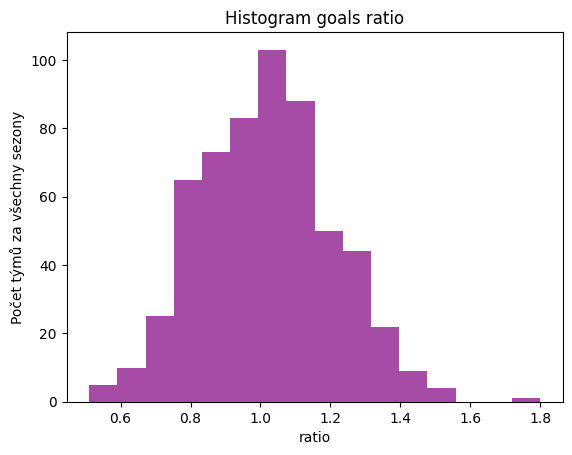

In [352]:
plt.hist(df['goals_ratio'].dropna(), bins= rice_rule(num_of_obs), color='purple', alpha=0.7)
plt.xlabel('ratio')
plt.ylabel('Počet týmů za všechny sezony')
plt.title('Histogram goals ratio')
plt.show()

### Histogram of the variable using the square root rule

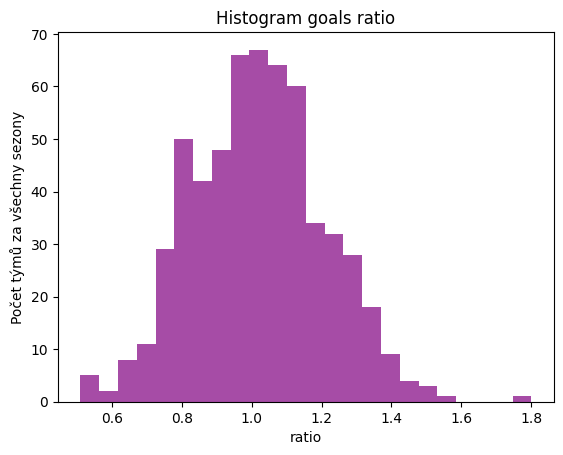

In [354]:
plt.hist(df['goals_ratio'].dropna(), bins= sq_root_rule(num_of_obs), color='purple', alpha=0.7)
plt.xlabel('ratio')
plt.ylabel('Počet týmů za všechny sezony')
plt.title('Histogram goals ratio')
plt.show()

# `victory_percentage`

Similar to the analysis of the variable `goals_ratio`, we will conduct an exploratory analysis of `victory_percentage` by following these steps:  
- Determine the basic descriptive statistics, such as the mean, median, standard deviation, minimum, and maximum.  
- Examine the distribution of the variable by using a histogram to better understand its characteristics.  
- Check if there are any obvious subgroups of teams within the variable under analysis that could be identified based on specific criteria, such as the range of the variable's values.

### Descriptive Statistics

In [358]:
df["victory_percentage"] = round((df["victories"]/(df["victories"]+df["defeats"]))*100,2)

In [374]:
agg_victory_percentage = df.groupby("team")["victory_percentage"].agg(["mean","std","max","min"]).round(2)

In [364]:
agg_victory_percentage[agg_victory_percentage["mean"]>50]
# winrate vyssi nez 50%

,mean,std,max,min
team,,,,
Anaheim Ducks,59.11,7.66,70.59,48.57
Boston Bruins,57.01,9.26,73.61,35.62
Buffalo Sabres,55.11,7.06,70.67,42.19
Calgary Flames,52.99,8.00,64.79,38.81
Carolina Hurricanes,52.54,8.41,70.27,33.85
Chicago Blackhawks,52.96,10.77,70.27,31.75
Colorado Avalanche,59.76,8.99,76.47,40.54
Dallas Stars,60.23,9.68,73.02,38.24
Detroit Red Wings,67.39,7.90,82.67,47.22


In [365]:
agg_victory_percentage[agg_victory_percentage["max"]>70]
#tymy ktere dosahli v sezone vetsiho winrate nez 70%

,mean,std,max,min
team,,,,
Anaheim Ducks,59.11,7.66,70.59,48.57
Boston Bruins,57.01,9.26,73.61,35.62
Buffalo Sabres,55.11,7.06,70.67,42.19
Carolina Hurricanes,52.54,8.41,70.27,33.85
Chicago Blackhawks,52.96,10.77,70.27,31.75
Colorado Avalanche,59.76,8.99,76.47,40.54
Dallas Stars,60.23,9.68,73.02,38.24
Detroit Red Wings,67.39,7.90,82.67,47.22
New Jersey Devils,61.52,6.68,71.64,49.23


In [368]:
#vyjimky
#tymy s prumernym winrate nad 60%
agg_victory_percentage["mean"].sort_values(ascending= False).head(3)

,mean
team,
Detroit Red Wings,67.39
New Jersey Devils,61.52
Dallas Stars,60.23


In [372]:
#maximalni dosazeny winrate nad 75%
agg_victory_percentage["max"].sort_values(ascending= False).head(3)

,max
team,
Detroit Red Wings,82.67
Washington Capitals,78.26
Colorado Avalanche,76.47


### Distribution

Here we will create the distribution of the variable, but we won't be doing it in two versions. Instead, we will choose a different, arbitrary number of intervals.

In [380]:
df.groupby("team")["goals_ratio"].quantile([0.25, 0.5, 0.75,1]).head(50
                                                                     )

team                       
Anaheim Ducks          0.25    0.9675
                       0.50    1.0250
                       0.75    1.0600
                       1.00    1.2400
Atlanta Thrashers      0.25    0.7600
                       0.50    0.8300
                       0.75    0.9150
                       1.00    1.0200
Boston Bruins          0.25    0.9500
                       0.50    1.1100
                       0.75    1.1800
                       1.00    1.4000
Buffalo Sabres         0.25    1.0400
                       0.50    1.0700
                       0.75    1.1400
                       1.00    1.2900
Calgary Flames         0.25    0.9000
                       0.50    1.0000
                       0.75    1.1400
                       1.00    1.3100
Carolina Hurricanes    0.25    0.9025
                       0.50    0.9700
                       0.75    1.0075
                       1.00    1.1300
Chicago Blackhawks     0.25    0.9200
                       0.50    1.0400
                       0.75    1.2100
                       1.00    1.3600
Colorado Avalanche     0.25    1.0500
                       0.50    1.1450
                       0.75    1.2600
                       1.00    1.4100
Columbus Blue Jackets  0.25    0.7850
                       0.50    0.8100
                       0.75    0.8300
                       1.00    0.9800
Dallas Stars           0.25    0.9800
                       0.50    1.1300
                       0.75    1.2575
                       1.00    1.4500
Detroit Red Wings      0.25    1.2200
                       0.50    1.2800
                       0.75    1.3400
                       1.00    1.8000
Edmonton Oilers        0.25    0.7900
                       0.50    0.9600
                       0.75    1.0200
                       1.00    1.1300
Florida Panthers       0.25    0.8500
                       0.50    0.9150
Name: goals_ratio, dtype: float64

# `goals_ratio` vs `victory_percentage`

We have already analyzed `goals_ratio` and `victory_percentage` as two separate variables. Now, our task is to analyze them together to identify potential interdependencies between them.  
  
In this step, we will perform the following exercises:  
- Before starting the analysis, let’s consider whether these variables might be dependent or independent of each other. What kind of relationship can be expected based on their business descriptions?  
- We will create a scatterplot to visually represent the dependencies between these variables.  
- We will determine the relationship between the variables based on the scatterplot.  
- We will analyze the scatterplot to identify any outliers, paying special attention to their common distribution.

## Scatterplot of Variables

Now let's create a scatterplot for the two analyzed variables, `goals_ratio` and `victory_percentage`. After completing this step, let's answer the following questions:  
- What is the relationship between the variables `goals_ratio` and `victory_percentage`?  
- Can any outliers be identified in the plot? If so, what criteria were used to identify them?

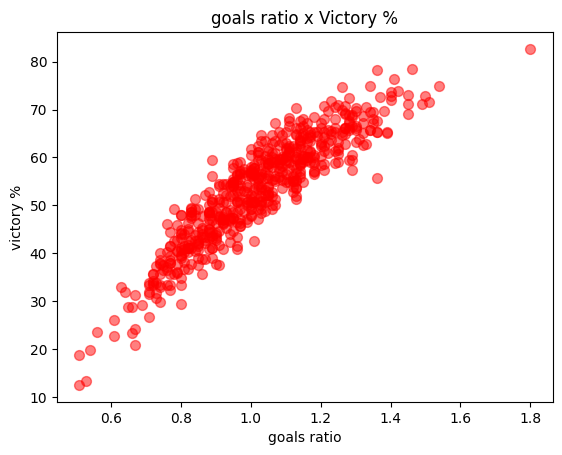

In [383]:
# Pozitivni korelace
plt.scatter(df['goals_ratio'], df['victory_percentage'], s=50, c='red', alpha=0.5)
plt.xlabel('goals ratio')
plt.ylabel('victory %')
plt.title('goals ratio x Victory %')
plt.show()

> space for chart analysis notes

If we have identified outlying observations at an earlier stage of analysis, let's now examine these specific cases. We will focus on outliers concerning the variables `goals_ratio` and `victory_percentage` to understand what features distinguish them.

The following steps should be taken for analysis:
1. Identify the specific outlying observations that were detected earlier.
2. Analyze the characteristics of these observations, paying attention to their values for the variables `goals_ratio` and `victory_percentage`.
3. Try to understand what might have caused their outlying nature. Are these instances of anomalies, or could they be the result of natural fluctuations in the data?

In [385]:
df[df["victory_percentage"] > 80]
# extremne dobry vykon, dalo se ocekavat z korelace

,team,season,victories,defeats,overtime_defeats,victory_percentage,scored_goals,received_goals,goal_difference,goals_ratio
126,Detroit Red Wings,1995,62,13,0,82.67,325,181,144,1.8


In [386]:
df[df["goals_ratio"]< 0.6]
# extremne spatny vykony dalo se ocekavat z korelace

,team,season,victories,defeats,overtime_defeats,victory_percentage,scored_goals,received_goals,goal_difference,goals_ratio
56,Ottawa Senators,1992,10,70,0,12.50,202,395,-193,0.51
60,San Jose Sharks,1992,11,71,0,13.41,218,414,-196,0.53
82,Ottawa Senators,1993,14,61,0,18.67,201,397,-196,0.51
193,Tampa Bay Lightning,1997,17,55,0,23.61,151,269,-118,0.56
225,Atlanta Thrashers,1999,14,57,4,19.72,170,313,-143,0.54


# Summary

In this notebook, we conducted a basic exploratory analysis of our dataset. The data was cleaned and then enriched with new variables, which we subjected to further analysis. The final step of this part is to save the processed data to a CSV file.  
  
**Let's save our data frame to the file:** `data/processed/hockey_teams.csv`, using a semicolon (`;`) as the column separator.

Next, in the following phase of our work, we will propose betting odds based on the analyzed historical data and discuss the results of this analysis.

### Writing the frame to the target location

- file name: `data/processed/hockey_teams.csv`,
- column separator: `;`,
- remember to disable index saving.

In [394]:
from google.colab import files
files.download("hockey_teams.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>